### Task 5: Run a series of lifetime DEL computations, varying model settings including: 
 - Amount of training data points for the ML models; e.g., 100, 200, 500, 1000, 5000… 
 - Number of points used for integration over the lifetime ($M$ = 103,104,105 …) 
- Multiple realizations with and without considering the effect of the climate uncertainty 
variable $X_W$

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

InputData = pd.read_excel('ML_ExampleDataSet.xlsx','InputVariables')
InputData = InputData.set_index('Sample_No',drop = False) # Make the "Sample_No" column as index of the data

TargetData = pd.read_excel('ML_ExampleDataSet.xlsx','LoadResults')
TargetData.set_index('PointNo', drop = False, inplace = True) # Make the "PointNo" column as index of the data

AllInputData = InputData.where(InputData['Sample_No']==TargetData['PointNo'])
AllTargetData = TargetData.where(TargetData['PointNo']==InputData['Sample_No'])
AllInputData.drop(columns = 'Sample_No', inplace = True)
AllTargetData.drop(columns = 'PointNo', inplace = True)
AllInputData = AllInputData[["U", "SigmaU", "Alpha"]]
nsamples = AllInputData['U'].count() # Find the total number of data points in the data frame
FeatureNames = AllInputData.columns.values
DependentVariableNames = AllTargetData.columns.values

# Load the provided data sets
wind_data = "HovsoreData_Sonic_100m_2004-2013.csv"
del_data = "ML_ExampleDataSet.xlsx"

# Outfput folder location for generated figures
output_figs = "figures/"
os.makedirs(output_figs, exist_ok=True)

# Read the data into pandas DataFrames
df_wind = pd.read_csv(wind_data)
df_del = pd.read_excel(del_data)

# Clean the data
df_wind = df_wind.dropna(subset=["Wsp","TI"])
df_wind = df_wind[(df_wind['Wsp'] > 0) & (df_wind['Wsp'] < 30) & (df_wind['TI'] > 0) & (df_wind['TI'] < 1)]

In [2]:
# -------------------------------------------------------------------
# Task 1: Joint distribution of input variables
# -------------------------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import scipy.optimize as optimize

# Windspeed (U) and turbulence intensity (TI) data
U = df_wind['Wsp'].values
SigmaU = df_wind['TI'].values * U  # Convert TI to standard deviation of wind speed


# === Fit Weibull to u (MLE - Most Likely Estimate) ===
k, _, A = stats.weibull_min.fit(U, floc=0)                  # WEIBULL Distribution fit (floc=0 -> forces the distribution to start at zero)


# === Bin by u, fit Lognormal to sigma_u per bin, then fit a trend curve ===
bins = np.arange(0, 35, 1.0)
centers, means, stds = [], [], []
# lo(wer) and hi(gher) bounds of each bin -> the sigmaU is fitted to the data in that bin
for lo, hi in zip(bins[:-1], bins[1:]):
    s = SigmaU[(U >= lo) & (U < hi)]
    if len(s) < 30:
        continue
    shape, _, scale = stats.lognorm.fit(s, floc=0)          # LOGNORMAL Distribution fit
    centers.append((lo + hi) / 2)
    means.append(scale * np.exp(0.5 * shape**2))
    stds.append(means[-1] * np.sqrt(np.exp(shape**2) - 1))

# Fit a quadratic curve to the mean -> that is what 2 is indicating 
p_mean = np.polyfit(centers, means, 2)
p_std = np.polyfit(centers, stds, 2)
u_max_fit = max(centers)  # clip point to avoid extrapolation blowing up

In [3]:
# -------------------------------------------------------------------
# Task 2: Uncertainty propagation for lifetime DEL
# -------------------------------------------------------------------
import numpy as np
from scipy import stats

def bootstrap_xw(U, block_days=None, Nbootstrap=5000, measurement_cov=0.01, joint_fit_cov=0.01, seed=1):
    rng = np.random.default_rng(seed)
    baseline_mean_u = np.mean(U)
    N = len(U)
    BootstrapMeans = np.empty(Nbootstrap)

    # IID bootstrap (no block structure)
    if block_days is None:
        for i in range(Nbootstrap):
            bootstrap_sample = rng.choice(U, size=N, replace=True)
            measurement_factor = (1.0 + rng.normal(0, measurement_cov))
            BootstrapMeans[i] = (np.mean(bootstrap_sample) * measurement_factor)

    # Block bootstrap
    else:
        block_size = int(block_days * 144) # 144 records/day
        for i in range(Nbootstrap):
            bootstrap_series = []
            while len(bootstrap_series) < N:
                start = rng.integers(0, N)
                idx = (np.arange(start, start + block_size) % N)
                bootstrap_series.extend(U[idx])
            bootstrap_series = np.asarray(bootstrap_series[:N])
            measurement_factor = (1.0 + rng.normal(0, measurement_cov))
            BootstrapMeans[i] = (np.mean(bootstrap_series)* measurement_factor)
    Xw_bootstrap = BootstrapMeans / baseline_mean_u
    joint_fit_factor = (1.0 + rng.normal(0, joint_fit_cov, Nbootstrap))
    Xw = Xw_bootstrap * joint_fit_factor

    return Xw[Xw > 0]

Xw_365d = bootstrap_xw(U, block_days=365)

In [4]:
# -------------------------------------------------------------------
# Task 3: ML Model for short-term load prediction
# -------------------------------------------------------------------
import sklearn
import sklearn.neural_network
from sklearn.utils import resample
from sklearn.neural_network import MLPRegressor

N_models = 50
ANN_models = []

# Fit the scalers once using all available training data
Xscaler = sklearn.preprocessing.StandardScaler().fit(AllInputData.values)
Yscaler = sklearn.preprocessing.StandardScaler().fit(
    AllTargetData["Blade_root_flapwise_M_x"].values.reshape(-1, 1)
)

X_all = Xscaler.transform(AllInputData.values)
Y_all = Yscaler.transform(
    AllTargetData["Blade_root_flapwise_M_x"].values.reshape(-1, 1)
).ravel()

for model_number in range(N_models):
    X_boot, Y_boot = resample(
        X_all,
        Y_all,
        replace=True,
        n_samples=len(X_all),
        random_state=model_number,
    )

    model = MLPRegressor(
        activation="tanh",
        hidden_layer_sizes=(8, 8),
        max_iter=5000,
        random_state=model_number,
    )

    model.fit(X_boot, Y_boot)
    ANN_models.append(model)


In [5]:
# -------------------------------------------------------------------
# Task 5: Lifetime DEL calculation
# -------------------------------------------------------------------
def run_lifetime_DEL(ANNmodel, Xscaler, Yscaler, N_outer=500, N_inner=10000, use_Xw=True, xw_samples=None):

    m = 10
    n_ref = 600
    N_life = 20 * 365 * 24 * 6
    LifetimeDELs = []

    if use_Xw:
        if xw_samples is None:
            xw_samples = Xw_365d
        if len(xw_samples) == 0:
            raise ValueError("xw_samples must contain at least one positive Xw sample")

    for i in range(N_outer):

        # Climate uncertainty
        if use_Xw:
            Xw = np.random.choice(xw_samples)
        else:
            Xw = 1.0

         # Sample surrogate-model uncertainty
        ANN_i = np.random.choice(ANN_models)

        # Sample the base environment, then propagate Xw before creating
        # the three features expected by the ANN.
        U_base_MC = stats.weibull_min.rvs(c=k, scale=A, size=N_inner)
        U_MC = Xw * U_base_MC
        U_clip = np.minimum(U_MC, u_max_fit)

        # SigmaU|U
        sigma_mean = np.polyval(p_mean, U_clip)
        sigma_std = np.polyval(p_std, U_clip)
        SigmaU_MC = np.random.normal(sigma_mean, sigma_std)
        SigmaU_MC = np.maximum(SigmaU_MC, 0.01)

        # Alpha|U
        Alpha_MC = np.random.normal(loc=0.1, scale=np.minimum(1.0,1.0/U_MC))

        # Get the Xmc
        X_MC = np.column_stack([U_MC, SigmaU_MC, Alpha_MC])

        # ANN was trained on [U, SigmaU, Alpha], so Xw is propagated
        # through U_MC and the conditional features before prediction.
        X_MC_scaled = Xscaler.transform(X_MC)

        Loads = Yscaler.inverse_transform(ANNmodel.predict(X_MC_scaled).reshape(-1,1)).flatten()
        Loads = np.maximum(Loads,0)
        MeanDamage = np.mean(Loads**m)
        DEL_LT = ((N_life/n_ref) * MeanDamage)**(1/m)
        LifetimeDELs.append(DEL_LT)

    return np.array(LifetimeDELs)

### A. Vary Training Set Size

In [6]:
all_data = AllInputData.size
training_sizes = [100, 200, 500, 1000, 5000, 10000, 20000, 25000]

for set in training_sizes:
    ratio = set / all_data
    print(f"Training size {set} -> {ratio * 100:.2f}%")

Training size 100 -> 0.33%
Training size 200 -> 0.67%
Training size 500 -> 1.67%
Training size 1000 -> 3.34%
Training size 5000 -> 16.70%
Training size 10000 -> 33.40%
Training size 20000 -> 66.80%
Training size 25000 -> 83.50%


In [7]:
MeanDEL = []
StdDEL = []

for Ntrain in training_sizes:

    X_subset = AllInputData.iloc[:Ntrain]
    Y_subset = AllTargetData.iloc[:Ntrain]

    Xscaler = sklearn.preprocessing.StandardScaler().fit(X_subset.values)
    Yscaler = sklearn.preprocessing.StandardScaler().fit(Y_subset['Blade_root_flapwise_M_x'].values.reshape(-1,1))

    Xtrain = Xscaler.transform(X_subset.values)
    Ytrain = Yscaler.transform(Y_subset['Blade_root_flapwise_M_x'].values.reshape(-1,1))

    ANNmodel = sklearn.neural_network.MLPRegressor(activation='tanh', hidden_layer_sizes=(8,8), max_iter=5000 ,random_state=1)
    ANNmodel.fit(Xtrain,Ytrain)

    DELs = run_lifetime_DEL(ANNmodel, Xscaler, Yscaler)
    MeanDEL.append(np.mean(DELs))
    StdDEL.append(np.std(DELs))

c:\Users\natal\repos\OceanCourses\.ocean\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1775: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\natal\repos\OceanCourses\.ocean\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1775: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\natal\repos\OceanCourses\.ocean\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1775: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\natal\repos\OceanCourses\.ocean\Lib\site-packages\sklearn\neural_network\_multilay

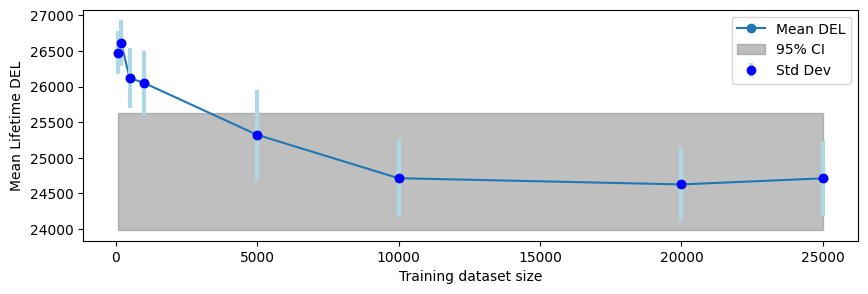

In [25]:
CI_low = np.percentile(DELs, 2.5)
CI_high = np.percentile(DELs, 97.5)

plt. figure(figsize=(10, 3))
plt.plot(training_sizes, MeanDEL, 'o-', label='Mean DEL')
plt.fill_between(training_sizes, CI_low, CI_high, color='gray', alpha=0.5, label='95% CI')
plt.errorbar(training_sizes, MeanDEL, yerr=StdDEL, fmt='o', color='blue', ecolor='lightblue', elinewidth=3, capsize=0, label='Std Dev')
plt.xlabel("Training dataset size")
plt.ylabel("Mean Lifetime DEL")
plt.legend()
plt.savefig(output_figs + "5.1_Mean_Lifetime_DEL_vs_training_size.png", dpi=300, bbox_inches="tight")

### B. Vary Integration Points

In [35]:
integration_sizes = [100, 1000, 10000, 100000]

DEL_mean = []
DEL_std = []

for M in integration_sizes:
    DELs = run_lifetime_DEL(ANNmodel, Xscaler, Yscaler, N_inner=M)
    DEL_mean.append(np.mean(DELs))
    DEL_std.append(np.std(DELs))

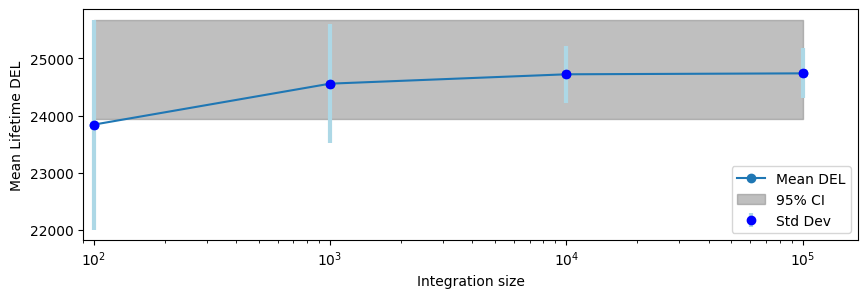

In [42]:
CI_low = np.percentile(DELs, 2.5)
CI_high = np.percentile(DELs, 97.5)

plt. figure(figsize=(10, 3))
plt.semilogx(integration_sizes, DEL_mean, 'o-', label='Mean DEL')
plt.fill_between(integration_sizes, CI_low, CI_high, color='gray', alpha=0.5, label='95% CI')
plt.errorbar(integration_sizes, DEL_mean, yerr=DEL_std, fmt='o', color='blue', ecolor='lightblue', elinewidth=3, capsize=0, label='Std Dev')
plt.xlim(left=90)
plt.legend(loc='lower right')
plt.xlabel("Integration size")
plt.ylabel("Mean Lifetime DEL")
plt.savefig(output_figs + "5.2_Mean_Lifetime_DEL_vs_integration_size.png", dpi=300, bbox_inches="tight")

### C. With and without Climate Uncertainty

In [12]:
DEL_with = run_lifetime_DEL(ANNmodel, Xscaler, Yscaler, use_Xw=True)
DEL_without = run_lifetime_DEL(ANNmodel, Xscaler, Yscaler, use_Xw=False)

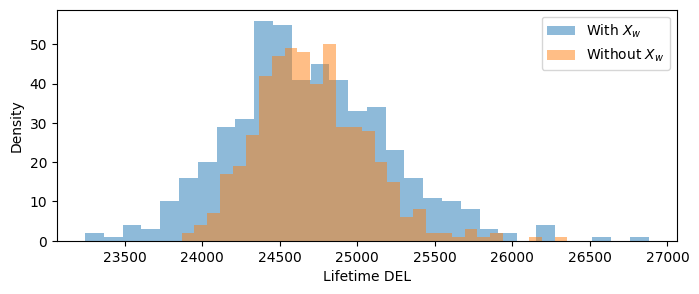

In [17]:
plt. figure(figsize=(8, 3))
plt.hist(DEL_with, alpha=0.5, bins=30, label=r'With $X_w$')
plt.hist(DEL_without, alpha=0.5, bins=30, label=r'Without $X_w$')
plt.xlabel("Lifetime DEL")
plt.ylabel("Density")
plt.legend()
plt.savefig(output_figs + "5.3_Lifetime_DEL_with_and_without_Xw.png", dpi=300, bbox_inches="tight")